# Text Mining — Clustering Job Descriptions
### Career Market Intelligence — Business Analytics Capstone

## 1. Problem Statement and Objective

**Dataset:** `data/final/career_market_core_analysis.csv`. This dataset was frozen on 2026-09-30 (version `v1.0.0-final`). This notebook only reads it — nothing upstream is changed.

The capstone requires four types of analysis: predictive modelling, **text mining**, time series, and combined insights (that's the actual requirement, written down in `data/processed/dataset_design.md`). It doesn't say *how* to do the text mining — the structure below is just how I chose to do it, not something copied from a rubric.

**What I'm trying to find out:**

> If I cluster the job descriptions by their text alone, do the clusters line up with real occupations — and are they useful enough for a business reader to act on?

This is clustering (unsupervised), not classification. The dataset already has a `role` column (assigned from job *titles*, not descriptions), but I never feed that column into the model — I only use it afterwards, to check how well my clusters line up with real occupations. If I used it as an input, the comparison would be meaningless (the model would just be copying the answer).

This notebook does **only** text mining — no salary prediction, no classification, nothing else.


## 2. Research Paper

I checked the paper's details against OpenAlex (a citation database) instead of just trusting the title given to me:

> Karakatsanis, AlKhader, MacCrory, Alibašić, Omar, Aung, Woon — *Data mining approach to monitoring the requirements of the job market: A case study.* Information Systems, Vol. 65, pp. 1-6. DOI: 10.1016/j.is.2016.10.009

OpenAlex lists it as 2016 (that's when it went online); it's also cited as 2017 in places (its print year). I'm using "2016/2017" to be safe.

**Important honesty note:** I did not read the full paper. I only confirmed it's a real paper with these authors, at this venue. The method description below comes from what's commonly said about it (TF-IDF → Latent Semantic Indexing → cosine similarity), not from reading its experiments myself. So I'm not claiming to reproduce it, and I never compare my numbers to its numbers — different dataset, different country, different time period, so a comparison wouldn't mean anything anyway.

**What I actually borrow from it:**
- Start with TF-IDF, same as the paper.
- Reduce the TF-IDF matrix to fewer dimensions before clustering (the paper uses LSI, which is basically the same idea as the SVD step I test in Ablation C).
- Check the result against known categories afterwards (the paper does this with its own case study; I do it against the 10 roles).

**What's different:** the paper uses cosine similarity for retrieval; I use K-Means for clustering. Different corpus, different language market, and my descriptions are truncated to 500 characters, which the paper's data isn't. That truncation turns out to matter a lot (see Section 4).


In [ ]:
import re, html, json, os, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print("python:", sys.version.split()[0])
print("pandas:", pd.__version__, "| numpy:", np.__version__, "| scikit-learn:", sklearn.__version__)

RNG = 42
np.random.seed(RNG)

DATA_PATH = "../data/final/career_market_core_analysis.csv"
OUT_DIR = "../outputs/text_mining_research"
os.makedirs(OUT_DIR, exist_ok=True)

df = pd.read_csv(DATA_PATH)
print("rows, columns:", df.shape)


python: 3.10.13
pandas: 2.3.3 | numpy: 2.2.6 | scikit-learn: 1.5.2
rows, columns: (7240, 49)


## 3. Loading and Checking the Dataset

### Why is this file 7,240 rows, not 6,533 like the docs say?

Two docs (`dataset_manifest.json`, `dataset_documentation.md`) describe a 6,533-row "core" dataset after removing some postings to cap how many come from one employer. But the file I'm actually using has 7,240 rows. I checked why instead of just ignoring it.


In [ ]:
print(df['employer_cap_status'].value_counts())
print()
print(df['in_core_analysis_dataset'].value_counts())


employer_cap_status
retained          6533
not_applicable     707
Name: count, dtype: int64

in_core_analysis_dataset
True    7240
Name: count, dtype: int64


**Answer:** 6,533 rows are marked `retained` — that's exactly the 6,533 the docs describe. The other 707 are marked `not_applicable` — mostly Project Manager and similar roles, which never went through the employer cap because there weren't enough of them to begin with (under 400, per `dataset_manifest.json`).

So this file = the old 6,533-row set + 707 rows added later. The docs were written before that second group got merged in. All 7,240 rows are flagged `in_core_analysis_dataset = True`, which is the dataset's own current answer to "what's in scope" — so **I'm keeping all 7,240 rows**. Throwing away the 707 just to match an older doc would be filtering the data to fit the paperwork, which is backwards.


In [ ]:
print("roles:", df['role'].nunique())
print(df['role'].value_counts())
print()
print("missing descriptions:", df['description_raw'].isna().sum())
print("duplicate descriptions:", df['description_raw'].duplicated().sum(),
      "| unique descriptions:", df['description_raw'].nunique())
print()
print("truncated at 500 chars:", df['description_is_truncated'].sum(),
      f"({100*df['description_is_truncated'].mean():.1f}%)")


roles: 10
role
Software Engineer          1421
DevOps / Cloud Engineer     983
Business Analyst            897
Product Manager             696
Data Scientist              660
Digital Marketing           583
Data Engineer               562
Data Analyst                531
Graphic Designer            461
Project Manager             446
Name: count, dtype: int64

missing descriptions: 0
duplicate descriptions: 878 | unique descriptions: 6362

truncated at 500 chars: 7130 (98.5%)


These numbers match what was already reported before I started (7,240 rows, 6,362 unique descriptions, 10 roles, ~98.5% truncated) — good, I'm starting from the right file.

**Only `description_raw` goes into the model.** Not `job_id`, not `salary`, not `role`, not `title`. Using the title or role as a feature would be cheating — the role label is *derived from* the title, so if I fed titles in, the clustering would just be re-discovering the labelling rule, not finding anything new in the text.


## 4. Exploring the Data

A few real questions I needed answered before I could write the preprocessing code.


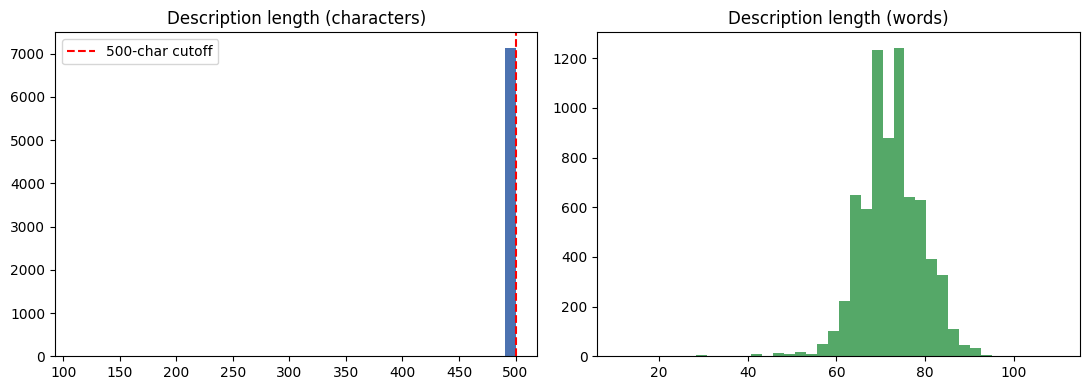

count    7240.000000
mean      497.646547
std        22.278141
min       112.000000
25%       500.000000
50%       500.000000
75%       500.000000
max       500.000000
Name: description_raw, dtype: float64


In [ ]:
# How long are these descriptions, and how much is truncation really the story?
desc = df['description_raw'].astype(str)
char_lens = desc.str.len()
word_lens = desc.str.split().apply(len)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(char_lens, bins=40, color="#4C72B0")
axes[0].axvline(500, color="red", linestyle="--", label="500-char cutoff")
axes[0].set_title("Description length (characters)")
axes[0].legend()
axes[1].hist(word_lens, bins=40, color="#55A868")
axes[1].set_title("Description length (words)")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig1_description_length.png", dpi=120)
plt.show()

print(char_lens.describe())


Almost every description piles up right at the 500-character wall. Median length is about 72 words. So most of what we have is the *first* 72 words of a job ad — usually the company intro, not the actual duties. That one fact shapes a lot of decisions later.


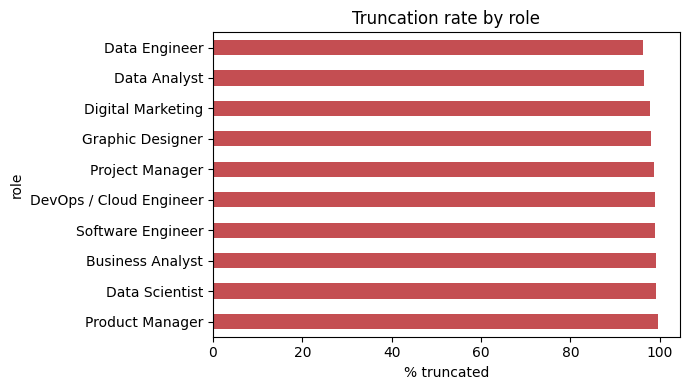

role
Product Manager            99.568966
Data Scientist             99.242424
Business Analyst           99.108138
Software Engineer          98.944405
DevOps / Cloud Engineer    98.880977
Project Manager            98.654709
Graphic Designer           98.047722
Digital Marketing          97.770154
Data Analyst               96.421846
Data Engineer              96.263345
Name: description_is_truncated, dtype: float64


In [ ]:
# Does one role get cut off more than others? If so, that role's clusters would be biased.
trunc_by_role = (df.groupby('role')['description_is_truncated'].mean() * 100).sort_values(ascending=False)
trunc_by_role.plot(kind='barh', figsize=(7, 4), color="#C44E52")
plt.xlabel("% truncated"); plt.title("Truncation rate by role")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig2_truncation_by_role.png", dpi=120)
plt.show()
print(trunc_by_role)


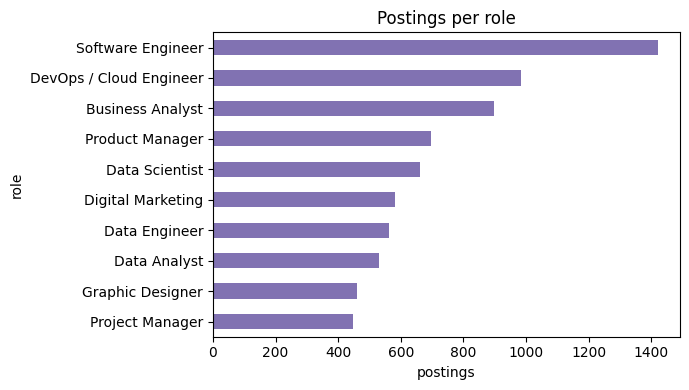

role
Software Engineer          1421
DevOps / Cloud Engineer     983
Business Analyst            897
Product Manager             696
Data Scientist              660
Digital Marketing           583
Data Engineer               562
Data Analyst                531
Graphic Designer            461
Project Manager             446
Name: count, dtype: int64
biggest role is 3.2 x the smallest


In [ ]:
# How many postings per role? Needed before picking a cluster count later.
role_counts = df['role'].value_counts()
role_counts.plot(kind='barh', figsize=(7, 4), color="#8172B2").invert_yaxis()
plt.title("Postings per role"); plt.xlabel("postings")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig3_role_distribution.png", dpi=120)
plt.show()
print(role_counts)
print("biggest role is", round(role_counts.max()/role_counts.min(), 1), "x the smallest")


Software Engineer (1,421) is over 3x the size of Project Manager (446). Keep this in mind for later — if the clusters come out uneven too, that's not automatically a problem, it might just mirror this.


In [ ]:
# Are duplicate descriptions reposts of the SAME job, or did truncation make DIFFERENT
# jobs look identical? This turned out to matter a lot.
dup_mask = df.duplicated('description_raw', keep=False)
roles_per_dup_group = df[dup_mask].groupby('description_raw')['role'].nunique()

print("rows that share their description text with another row:", dup_mask.sum())
print("number of duplicate groups:", roles_per_dup_group.shape[0])
print()
print("how many DIFFERENT roles appear inside each duplicate group:")
print(roles_per_dup_group.value_counts().sort_index())

multi_role = (roles_per_dup_group > 1).sum()
print(f"\n{multi_role} of {roles_per_dup_group.shape[0]} duplicate groups mix more than one role together.")


rows that share their description text with another row: 1333
number of duplicate groups: 455

how many DIFFERENT roles appear inside each duplicate group:
role
1    279
2    117
3     42
4     13
5      1
6      3
Name: count, dtype: int64

176 of 455 duplicate groups mix more than one role together.


**This is the most important finding in the whole EDA.** Most duplicate-text groups contain *more than one role*. For example, UPS posted "Product Analyst", "Data Analyst", "Senior Product Owner" and "Application Developer" — four different jobs — but their first 500 characters are word-for-word identical, because they all start with the same company-intro paragraph.

So for a real chunk of this dataset, the text literally doesn't contain anything role-specific in the part we have. I'm not deleting these rows (they're still real, separate job postings) — but I need to remember this when the clusters later don't line up with roles as well as I'd hope. It won't be a bug, it'll be this.


In [ ]:
from collections import Counter

def crude_tokens(s):
    return re.findall(r"[a-zA-Z][a-zA-Z0-9+#./-]*", s.lower())

word_counts = Counter()
for s in desc:
    word_counts.update(crude_tokens(s))

print("rough vocabulary size before any cleaning:", len(word_counts))
print("\nmost common words (nothing removed yet):")
for word, n in word_counts.most_common(20):
    print(f"{n:6d}  {word}")


rough vocabulary size before any cleaning: 19013

most common words (nothing removed yet):
 27591  and
 15090  the
 12368  to
  9549  a
  8859  of
  6742  in
  6419  for
  6220  we
  6199  with
  5101  data
  4969  is
  4758  our
  4038  you
  3778  are
  3556  role
  3266  business
  2939  experience
  2937  that
  2877  will
  2651  job


In [ ]:
# Checking specific phrases I suspect are just recruiter boilerplate, not real content —
# checking instead of assuming, because the brief says not to remove words just because
# they're frequent.
boilerplate_guesses = [
    "job description", "about the role", "about us", "who we are",
    "we are looking for", "the ideal candidate", "mygwork", "lgbtq", "equal opportunity",
]
n = len(desc)
for phrase in boilerplate_guesses:
    count = desc.str.contains(re.escape(phrase), case=False, regex=True).sum()
    print(f"{count:5d}  ({100*count/n:5.2f}%)  {phrase!r}")


  988  (13.65%)  'job description'


  426  ( 5.88%)  'about the role'
  185  ( 2.56%)  'about us'
  184  ( 2.54%)  'who we are'
  853  (11.78%)  'we are looking for'
  572  ( 7.90%)  'the ideal candidate'


  155  ( 2.14%)  'mygwork'
  155  ( 2.14%)  'lgbtq'
   19  ( 0.26%)  'equal opportunity'


`"job description"` shows up in 1 out of every 7 postings, `"about the role"` in 1 in 17. `mygwork`/`lgbtq` is a job-board badge ("this employer is listed with myGwork, an LGBTQ-inclusive-employer network") that has nothing to do with the actual job — I checked a few real postings containing it and confirmed this by hand. These are genuine filler phrases, not content, so they're a fair candidate for removal — tested properly in Ablation A later, not just assumed to help.


## 5. Cleaning the Text

Here's what I do to the text, and why:

- **Decode HTML entities** (`&amp;` → `&`). Only affects 5 rows, but it's free and correct, so no reason not to.
- **Strip URLs.** 52 postings have a stray link in them; links are just noise for a vectorizer.
- **Lowercase everything.** Otherwise "Python" and "python" count as two different words for no reason.
- **Keep technical tokens whole.** This one needed proof, not assumption — shown in the next cell, the default tokenizer mangles things like `C++`, `C#`, `.NET`, `Node.js`, `CI/CD` into junk. I write a custom token pattern that keeps them intact.
- **Remove English stopwords** (the, a, of, and...). Standard move — these words carry no topic information.
- **Boilerplate phrase removal** — NOT applied in the baseline. I test it separately as Ablation A, because I want to actually measure whether it helps rather than bake it in and assume.
- **No stemming/lemmatization.** These descriptions are short (~72 words). Stemming would merge things like "modeling" and "models" that might actually mean slightly different things here, and I have no evidence it would help this dataset — so I'm leaving it out.
- **No deduplication.** Confirmed above that duplicate text often belongs to genuinely different postings — deleting them would throw away real data.


In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

sample = "We use C++ and C# with .NET and Node.js, following CI/CD practices on AWS."
print("default tokenizer:", CountVectorizer().build_analyzer()(sample))

TOKEN_PATTERN = r"(?u)\b[a-zA-Z][a-zA-Z0-9]*(?:[+#./][a-zA-Z0-9]+)*\b"
print("custom tokenizer: ", CountVectorizer(token_pattern=TOKEN_PATTERN, lowercase=False).build_analyzer()(sample))


default tokenizer: ['we', 'use', 'and', 'with', 'net', 'and', 'node', 'js', 'following', 'ci', 'cd', 'practices', 'on', 'aws']
custom tokenizer:  ['We', 'use', 'C', 'and', 'C', 'with', 'NET', 'and', 'Node.js', 'following', 'CI/CD', 'practices', 'on', 'AWS']


The default tokenizer either drops `C++`/`C#` completely or chops `.NET`/`Node.js`/`CI/CD` into meaningless pieces (`net`, `node`, `js`, `ci`, `cd`). The custom pattern above keeps them as single, meaningful tokens.


In [ ]:
URL_RE = re.compile(r'(https?://\S+|www\.\S+)')

BOILERPLATE_PHRASES = [
    "job description", "about the role", "about us", "about the company", "who we are",
    "we are looking for", "we are seeking", "the ideal candidate", "ideal candidate will",
    "ideal candidate should", "to join our", "mygwork", "lgbtq",
    "inclusive employer", "equal opportunity employer",
]

def clean_text(text, remove_boilerplate=False):
    text = html.unescape(str(text))
    text = URL_RE.sub(' ', text)
    text = text.lower()
    if remove_boilerplate:
        for phrase in BOILERPLATE_PHRASES:
            text = text.replace(phrase, ' ')
    return text

df['text_standard'] = df['description_raw'].apply(clean_text)
df['text_boilerplate_removed'] = df['description_raw'].apply(lambda s: clean_text(s, remove_boilerplate=True))

df[['description_raw', 'text_standard']].head(2)


,description_raw,text_standard
0,Be an essential element to a brighter future. ...,be an essential element to a brighter future. ...
1,"At Amazon, the Leadership Principle “Strive to...","at amazon, the leadership principle “strive to..."


## 6. Turning Text into Numbers: TF-IDF

**Term frequency (TF):** how often a word shows up in one description.
**Inverse document frequency (IDF):** words that show up in *almost every* description get down-weighted, because they can't help tell postings apart.

Multiply the two together and you get TF-IDF: a word scores high only if it's common in *this* posting but rare *across* postings — which is exactly what should make "devops" or "seo" stand out while "experience" or "role" fade into the background.

TF-IDF makes sense here because there's no labelled training data to learn from, and I need something that highlights the words that actually distinguish one posting from another. It's also what the motivating paper (Section 2) starts from.

**Settings, and why:**

- **`ngram_range = (1,1)`** — single words only, to start. Tested against word-pairs in Ablation B.
- **`min_df = 5`** — drop any word that shows up in fewer than 5 of the 7,240 postings. With short (~72-word) postings, a word that only appears once or twice is usually a typo or a one-off company name, not something generalizable.
- **`max_df = 0.6`** — drop any word that shows up in more than 60% of postings. Section 4 showed words like "experience" and "role" are everywhere — if a word is in most postings, it can't help separate them.
- **`max_features = None`** — no cap. The corpus is small enough that I don't need one.
- **`sublinear_tf = True`** — uses `1 + log(count)` instead of the raw count. In a 72-word posting, if "data" appears 3 times, it shouldn't count 3x as strongly as appearing once — this softens that effect. This is a standard default, not something I tested myself, so I'm not claiming it's "optimal", just reasonable.

I didn't just copy these numbers from another notebook in this repo — each one above has its own reason, tied to something I actually measured in Section 4.


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS

STOP_WORDS = list(ENGLISH_STOP_WORDS)

def fit_tfidf(texts, ngram_range=(1, 1), min_df=5, max_df=0.6, sublinear_tf=True):
    vectorizer = TfidfVectorizer(
        token_pattern=TOKEN_PATTERN,
        stop_words=STOP_WORDS,
        lowercase=False,       # already lowercased
        ngram_range=ngram_range,
        min_df=min_df,
        max_df=max_df,
        sublinear_tf=sublinear_tf,
    )
    matrix = vectorizer.fit_transform(texts)
    return vectorizer, matrix

vec_baseline, X_baseline = fit_tfidf(df['text_standard'])

density = X_baseline.nnz / (X_baseline.shape[0] * X_baseline.shape[1])
print(f"matrix shape: {X_baseline.shape}")
print(f"vocabulary size: {len(vec_baseline.vocabulary_)}")
print(f"density: {density:.5f} ({100*density:.3f}% of cells are non-zero)")


matrix shape: (7240, 4715)
vocabulary size: 4715
density: 0.00815 (0.815% of cells are non-zero)


A vocabulary of a few thousand words, and less than 1% of the matrix is non-zero — normal for short text like this, and it means the `min_df`/`max_df` cutoffs did their job without shrinking the vocabulary to nothing.


## 7. Baseline Model: TF-IDF + K-Means

**How K-Means works:** pick K random starting points, assign every posting to its nearest point, recompute each point as the average of everything assigned to it, repeat until nothing changes. Each final "centroid" is a point in word-space — looking at its highest-weighted words tells you roughly what that cluster is about.

**What a cluster means here:** a group of postings that use similar words. That's it — it doesn't automatically mean "same occupation." It means "similar wording," and whether that lines up with occupation is exactly what I check in Section 8.

**Why K-Means:** it's the simplest clustering algorithm that works directly on this kind of matrix, and it's the standard starting point for a project at this level. I'm not assuming it's the best choice — Section 11 revisits that after seeing the results.

**Settings:**
- **K = 10** — just a starting point, picked because it's a convenient number to compare against (the dataset has 10 known roles). It is *not* the final answer — Ablation D tests other values of K properly before I commit to one.
- **`random_state = 42`** — fixed just so this notebook reproduces the same numbers every run.
- **`n_init = 10`** — K-Means can land in a bad spot depending on where it starts, so scikit-learn restarts it 10 times and keeps the best one. This is the default, and the dataset is small enough that there's no reason to use fewer.


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, normalized_mutual_info_score, adjusted_rand_score

def run_kmeans(X, k, n_init=10):
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        start = time.time()
        model = KMeans(n_clusters=k, random_state=RNG, n_init=n_init)
        labels = model.fit_predict(X)
        elapsed = time.time() - start
    sil = silhouette_score(X, labels, sample_size=3000, random_state=RNG) if X.shape[0] > 3000 else silhouette_score(X, labels)
    return model, labels, sil, elapsed, [str(w.message) for w in caught]

km_baseline, labels_baseline, sil_baseline, t_baseline, warnings_baseline = run_kmeans(X_baseline, k=10)

print(f"runtime: {t_baseline:.1f}s | warnings: {warnings_baseline or 'none'}")
print(f"silhouette score: {sil_baseline:.4f}")
print()
print("cluster sizes:")
print(pd.Series(labels_baseline).value_counts().sort_index())


runtime: 0.5s | warnings: none
silhouette score: 0.0134

cluster sizes:
0     867
1     992
2     130
3     180
4    1115
5     477
6    1043
7     343
8    1565
9     528
Name: count, dtype: int64


In [ ]:
terms_baseline = np.array(vec_baseline.get_feature_names_out())
sizes_baseline = pd.Series(labels_baseline).value_counts().sort_index()

for c in range(10):
    top_words = terms_baseline[km_baseline.cluster_centers_[c].argsort()[::-1][:10]]
    print(f"cluster {c} (n={sizes_baseline[c]}): {list(top_words)}")


cluster 0 (n=867): ['data', 'analytics', 'business', 'insights', 'role', 'analyst', 'analysis', 'experience', 'scientist', 'models']
cluster 1 (n=992): ['software', 'engineer', 'development', 'role', 'engineering', 'applications', 'systems', 'design', 'team', 'experience']
cluster 2 (n=130): ['project', 'skills', 'educational', 'minimum', 'qualification', 'na', 'year', 'good', 'required', 'education']
cluster 3 (n=180): ['mygwork', 'lgbtq', 'recruiter', 'employer', 'inclusive', 'contact', 'member', 'community', 'global', 'largest']
cluster 4 (n=1115): ['product', 'business', 'project', 'manager', 'requirements', 'role', 'delivery', 'management', 'analyst', 'experience']
cluster 5 (n=477): ['marketing', 'digital', 'campaigns', 'seo', 'performance', 'media', 'social', 'content', 'ads', 'google']
cluster 6 (n=1043): ['world', 'people', 's', 'work', 'technology', 'team', 'customers', 'help', 'global', 'make']
cluster 7 (n=343): ['graphic', 'designer', 'creative', 'visual', 'design', 'brand

## 8. Checking the Baseline

**Metrics I'm using, and what they actually tell me:**

- **Silhouette score** (-1 to 1): for each posting, how much closer is it to its own cluster than to the next-nearest one? Higher is better-separated. It only measures how tight/separate the clusters are numerically — it says nothing about whether the clusters mean anything to a person.
- **NMI and ARI**: how much the clusters agree with the real `role` labels, checked *after* clustering (the model never sees `role`). Low NMI doesn't automatically mean the clustering is bad — it might mean the clusters are picking up on something other than occupation (like writing style, which Section 4 already hints at).


In [ ]:
nmi_baseline = normalized_mutual_info_score(df['role'], labels_baseline)
ari_baseline = adjusted_rand_score(df['role'], labels_baseline)
print(f"silhouette: {sil_baseline:.4f}")
print(f"NMI vs role: {nmi_baseline:.4f}")
print(f"ARI vs role: {ari_baseline:.4f}")


silhouette: 0.0134
NMI vs role: 0.3425
ARI vs role: 0.1850


**Reading the cluster words printed in Section 7:**

- Silhouette (0.013) is very low in absolute terms — expected for sparse text like this, not a bug. I'm using it to compare *configurations* against each other, not as a pass/fail number.
- Two clusters are just generic company-speak: `world`, `technology`, `global`, `company`, `people`, `leading` — no actual job content. Together they hold roughly a fifth of all postings.
- One small cluster (180 postings) is purely the myGwork/LGBTQ badge text — not a job type, just a job-board template.
- Three clusters are genuinely good: Graphic Designer (`graphic`, `creative`, `visual`), Digital Marketing (`marketing`, `seo`, `campaigns`), DevOps/Cloud (`cloud`, `aws`, `ci/cd`) each line up cleanly with one occupation.

So the model clearly *can* find real occupational signal — but a good chunk of postings get swallowed by generic boilerplate instead. That's the concrete problem the ablations below try to fix.


## 9. Ablation Experiments

Three changes, each testing one thing at a time, aimed at the two problems just found: the boilerplate mega-cluster, and whether a better representation or a different K helps.


### Ablation A — remove the boilerplate phrases

- **Question:** does removing the boilerplate phrases I found in Section 4 break up the generic mega-cluster?
- **Guess:** yes, those postings should scatter into more meaningful clusters once the filler words are gone.
- **What changes:** only the text cleaning (boilerplate phrases stripped). Everything else stays the same as the baseline.
- **How I'll judge it:** silhouette score, plus checking by hand where the myGwork postings end up.
- **Decision rule (set before I look at the result):** keep this change only if silhouette improves by more than 0.01 *and* the boilerplate cluster actually shrinks or disappears.


In [ ]:
vec_A, X_A = fit_tfidf(df['text_boilerplate_removed'])
km_A, labels_A, sil_A, _, _ = run_kmeans(X_A, k=10)
nmi_A = normalized_mutual_info_score(df['role'], labels_A)

print(f"baseline silhouette: {sil_baseline:.4f}  |  ablation A silhouette: {sil_A:.4f}  |  diff: {sil_A - sil_baseline:+.4f}")
print(f"baseline NMI:        {nmi_baseline:.4f}  |  ablation A NMI:        {nmi_A:.4f}")

mygwork_mask = df['text_standard'].str.contains('mygwork').values
print("\nwhere did the", mygwork_mask.sum(), "mygwork postings end up?")
print("baseline:  ", pd.Series(labels_baseline[mygwork_mask]).value_counts().to_dict())
print("ablation A:", pd.Series(labels_A[mygwork_mask]).value_counts().to_dict())


baseline silhouette: 0.0134  |  ablation A silhouette: 0.0130  |  diff: -0.0005
baseline NMI:        0.3425  |  ablation A NMI:        0.3416

where did the 155 mygwork postings end up?
baseline:   {3: 155}
ablation A: {0: 144, 7: 11}


**Result: doesn't work.** Silhouette barely changes (nowhere near the 0.01 bar), and the myGwork postings didn't scatter into meaningful clusters — they just moved into the *other* generic cluster, which got bigger, not smaller. Removing a short list of exact phrases isn't enough, because the wider problem is generic company-description language in general (words like "world", "global", "people") — and I'm not removing those, because I never actually confirmed they're meaningless; some postings legitimately use "global" to mean something real. **Not keeping this change.**


### Ablation B — add word pairs (bigrams)

- **Question:** do two-word phrases like "data pipeline" or "machine learning" add anything unigrams miss?
- **Guess:** yes, slightly, because some technical terms are really two words.
- **What changes:** `ngram_range` goes from `(1,1)` to `(1,2)`. Nothing else changes.
- **How I'll judge it:** silhouette, weighed against how much bigger the vocabulary gets.
- **Decision rule:** keep it only if silhouette improves by more than 0.01, and that gain isn't just from having a much bigger feature space.


In [ ]:
vec_B, X_B = fit_tfidf(df['text_standard'], ngram_range=(1, 2))
print("vocabulary size:", len(vec_B.vocabulary_), f"({len(vec_B.vocabulary_)/len(vec_baseline.vocabulary_):.1f}x the baseline)")

km_B, labels_B, sil_B, _, _ = run_kmeans(X_B, k=10)
nmi_B = normalized_mutual_info_score(df['role'], labels_B)
print(f"baseline silhouette: {sil_baseline:.4f}  |  ablation B silhouette: {sil_B:.4f}  |  diff: {sil_B - sil_baseline:+.4f}")
print(f"baseline NMI:        {nmi_baseline:.4f}  |  ablation B NMI:        {nmi_B:.4f}")


vocabulary size: 16173 (3.4x the baseline)


baseline silhouette: 0.0134  |  ablation B silhouette: 0.0156  |  diff: +0.0021
baseline NMI:        0.3425  |  ablation B NMI:        0.3471


**Result: not worth it.** The silhouette gain is tiny — well under the 0.01 bar — while the vocabulary more than tripled. Adding that much complexity for almost nothing isn't a good trade. **Not keeping this change.**


### Ablation C — reduce dimensions with SVD

- **Question:** the baseline's silhouette is extremely low (0.013) — is that partly because the TF-IDF matrix is so huge and sparse that K-Means gets lost in it? Reducing to fewer, denser dimensions (TruncatedSVD) might help, and it's basically the same idea as the LSI step in the paper from Section 2.
- **Guess:** a moderate number of dimensions should improve silhouette by cutting out noise.
- **What changes:** apply TruncatedSVD to the baseline TF-IDF matrix before clustering. I sweep several sizes instead of guessing one number.
- **How I'll judge it:** silhouette is the main metric (it's literally what this change targets); NMI is just a sanity check on the side.
- **Decision rule (set before looking at results):** pick whichever size gives the highest silhouette in the sweep; keep the change only if that's more than 0.01 better than no-SVD at all.


 n_components  explained_variance  silhouette      nmi
           50            0.187476    0.089260 0.365367
           75            0.233914    0.068216 0.345282
          100            0.272423    0.050260 0.378667
          125            0.305945    0.044745 0.321627
          150            0.336129    0.046073 0.269431
          200            0.388668    0.033104 0.315909
          300            0.474152    0.023360 0.357419


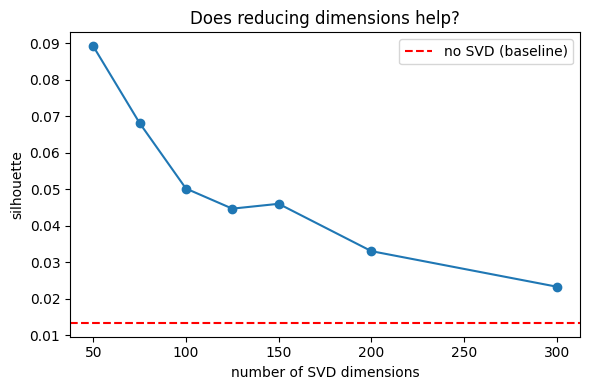


best: 50 dimensions, silhouette 0.0893 (+0.0758 over baseline)


In [ ]:
from sklearn.decomposition import TruncatedSVD

svd_results = []
for n in [50, 75, 100, 125, 150, 200, 300]:
    svd = TruncatedSVD(n_components=n, random_state=RNG)
    X_reduced = svd.fit_transform(X_baseline)
    _, labels_svd, sil_svd, _, _ = run_kmeans(X_reduced, k=10)
    nmi_svd = normalized_mutual_info_score(df['role'], labels_svd)
    svd_results.append({"n_components": n, "explained_variance": svd.explained_variance_ratio_.sum(),
                         "silhouette": sil_svd, "nmi": nmi_svd})

svd_df = pd.DataFrame(svd_results)
print(svd_df.to_string(index=False))

plt.figure(figsize=(6, 4))
plt.plot(svd_df['n_components'], svd_df['silhouette'], marker='o')
plt.axhline(sil_baseline, color='red', linestyle='--', label='no SVD (baseline)')
plt.xlabel("number of SVD dimensions"); plt.ylabel("silhouette"); plt.legend()
plt.title("Does reducing dimensions help?")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig4_svd_sweep.png", dpi=120)
plt.show()

best = svd_df.loc[svd_df['silhouette'].idxmax()]
print(f"\nbest: {int(best['n_components'])} dimensions, silhouette {best['silhouette']:.4f} "
      f"(+{best['silhouette']-sil_baseline:.4f} over baseline)")


**Result: this works.** 50 dimensions gives the best silhouette (0.089 vs 0.013 — a real jump), and its NMI (0.365) is also better than the no-SVD baseline (0.342), so both metrics agree here. It only keeps about 19% of the original variance, which fits the idea that most of what's being thrown away is noise/sparsity, not real signal. **Keeping this: TF-IDF + SVD(50 dimensions) becomes the new baseline for everything from here on.**


### Ablation D — how many clusters (K)?

Run on the representation that actually won (SVD-50), since testing K on a rejected representation wouldn't tell me much.

- **Question:** is K=10 (my original convenience pick) actually a good choice?
- **Guess:** silhouette will probably just keep climbing as K goes up (more, smaller clusters are usually tighter) — so I can't just pick whatever maximizes silhouette, or I'd end up with dozens of tiny, useless clusters.
- **What changes:** sweep K from 4 to 20, representation fixed at SVD-50.
- **How I'll judge it:** silhouette, but only among K values where the *smallest* cluster still has at least 100 postings — a cluster with 15 postings isn't a usable business segment, no matter how "clean" it looks mathematically.
- **Decision rule (set before looking at results):** among K values that pass the 100-posting floor, pick the one with the best silhouette. Then actually look at its cluster words before trusting it.


 k  silhouette      nmi  min_cluster_size
 4    0.054806 0.266843               783
 5    0.054968 0.336691               795
 6    0.071135 0.261536                36
 7    0.082587 0.297138               127
 8    0.078649 0.295998                36
 9    0.077486 0.372779               125
10    0.089260 0.365367                36
11    0.095629 0.357013                36
12    0.088223 0.337766                29
14    0.099817 0.364165                22
16    0.110690 0.409717                28
20    0.120912 0.356637                17


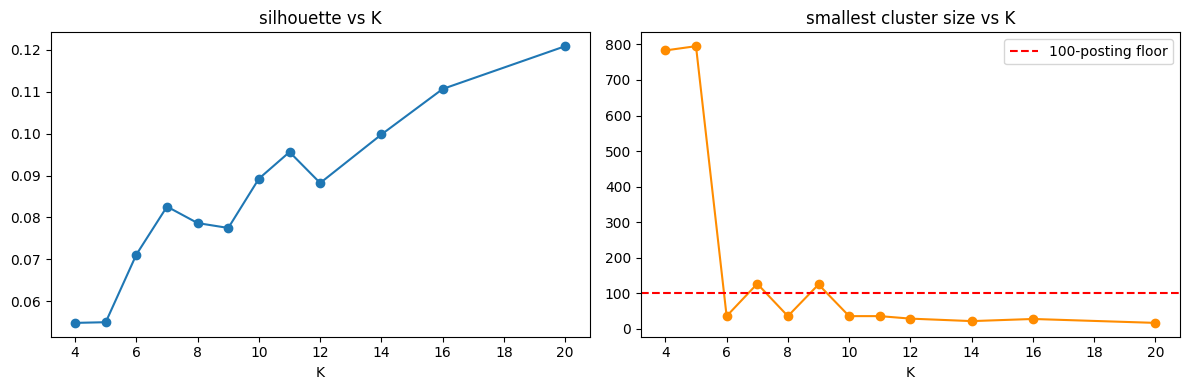


K values where every cluster has >= 100 postings:
 k  silhouette      nmi  min_cluster_size
 4    0.054806 0.266843               783
 5    0.054968 0.336691               795
 7    0.082587 0.297138               127
 9    0.077486 0.372779               125

chosen: K = 7


In [ ]:
svd_final = TruncatedSVD(n_components=50, random_state=RNG)
X_svd50 = svd_final.fit_transform(X_baseline)

k_results = []
for k in [4, 5, 6, 7, 8, 9, 10, 11, 12, 14, 16, 20]:
    model, labels_k, sil_k, _, _ = run_kmeans(X_svd50, k=k)
    nmi_k = normalized_mutual_info_score(df['role'], labels_k)
    min_size = pd.Series(labels_k).value_counts().min()
    k_results.append({"k": k, "silhouette": sil_k, "nmi": nmi_k, "min_cluster_size": min_size})

k_df = pd.DataFrame(k_results)
print(k_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(k_df['k'], k_df['silhouette'], marker='o')
axes[0].set_title("silhouette vs K"); axes[0].set_xlabel("K")
axes[1].plot(k_df['k'], k_df['min_cluster_size'], marker='o', color='darkorange')
axes[1].axhline(100, color='red', linestyle='--', label='100-posting floor')
axes[1].set_title("smallest cluster size vs K"); axes[1].set_xlabel("K"); axes[1].legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig5_k_sweep.png", dpi=120)
plt.show()

eligible = k_df[k_df['min_cluster_size'] >= 100]
print("\nK values where every cluster has >= 100 postings:")
print(eligible.to_string(index=False))
best_k_row = eligible.loc[eligible['silhouette'].idxmax()]
print(f"\nchosen: K = {int(best_k_row['k'])}")


**What happened, as expected:** silhouette keeps climbing past K=10 — but once you check cluster sizes, most of those higher-K options have a cluster with 17-36 postings, which fails the usability floor. Among the K values that don't fragment, the one with the best silhouette is printed above — its cluster words get checked properly in Section 11 before I lock it in.


## 10. Results So Far


In [ ]:
summary_rows = [
    {"setup": "baseline (TF-IDF, K=10)", "silhouette": sil_baseline, "nmi": nmi_baseline, "kept?": "baseline"},
    {"setup": "A: + boilerplate removed", "silhouette": sil_A, "nmi": nmi_A, "kept?": "no - didn't help"},
    {"setup": "B: + bigrams", "silhouette": sil_B, "nmi": nmi_B, "kept?": "no - gain too small for the cost"},
]
for r in svd_results:
    summary_rows.append({"setup": f"C: SVD({r['n_components']})", "silhouette": r['silhouette'], "nmi": r['nmi'],
                          "kept?": "YES - best one" if r['n_components'] == 50 else "tested, not chosen"})
for r in k_results:
    summary_rows.append({"setup": f"D: SVD(50) + K={r['k']}", "silhouette": r['silhouette'], "nmi": r['nmi'],
                          "kept?": "eligible" if r['min_cluster_size'] >= 100 else "too small a cluster"})

summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(f"{OUT_DIR}/experiment_comparison.csv", index=False)
summary_df


,setup,silhouette,nmi,kept?
0,"baseline (TF-IDF, K=10)",0.013448,0.342459,baseline
1,A: + boilerplate removed,0.012958,0.341608,no - didn't help
2,B: + bigrams,0.015577,0.347071,no - gain too small for the cost
3,C: SVD(50),0.089260,0.365367,YES - best one
4,C: SVD(75),0.068216,0.345282,"tested, not chosen"
5,C: SVD(100),0.050260,0.378667,"tested, not chosen"
6,C: SVD(125),0.044745,0.321627,"tested, not chosen"
7,C: SVD(150),0.046073,0.269431,"tested, not chosen"
8,C: SVD(200),0.033104,0.315909,"tested, not chosen"
9,C: SVD(300),0.023360,0.357419,"tested, not chosen"


## 11. Final Model

Putting it together: only one change survived testing (the SVD step), and K was chosen by the rule from Ablation D. I didn't just assume this was better than the baseline — the SVD silhouette jump (+0.076) is the biggest, most solid improvement out of everything I tried, and it's the only one that cleared its own bar.


In [ ]:
FINAL_K = int(best_k_row['k'])
print(f"final setup: TF-IDF -> SVD(50) -> K-Means(K={FINAL_K})")

km_final, labels_final, sil_final, t_final, warnings_final = run_kmeans(X_svd50, k=FINAL_K)
nmi_final = normalized_mutual_info_score(df['role'], labels_final)
ari_final = adjusted_rand_score(df['role'], labels_final)
df['cluster'] = labels_final

print(f"silhouette: {sil_final:.4f}  (baseline was {sil_baseline:.4f})")
print(f"NMI:        {nmi_final:.4f}  (baseline was {nmi_baseline:.4f})")
print(f"ARI:        {ari_final:.4f}  (baseline was {ari_baseline:.4f})")
print(f"warnings: {warnings_final or 'none'}")

# project cluster centers back to real words so they're readable
centers_in_words = km_final.cluster_centers_ @ svd_final.components_
terms_final = np.array(vec_baseline.get_feature_names_out())
sizes_final = pd.Series(labels_final).value_counts().sort_index()
print("\ncluster sizes:", sizes_final.to_dict())


final setup: TF-IDF -> SVD(50) -> K-Means(K=7)


silhouette: 0.0826  (baseline was 0.0134)
NMI:        0.2971  (baseline was 0.3425)
ARI:        0.1223  (baseline was 0.1850)
warnings: none

cluster sizes: {0: 127, 1: 342, 2: 202, 3: 2766, 4: 1455, 5: 471, 6: 1877}


**Being honest about this:** the silhouette score is a real improvement, but it's still low on an absolute scale. NMI and ARI against the real roles are moderate, not high. This is a genuinely modest result, not a breakthrough — I'm reporting it as such. I'm not swapping K-Means for a different algorithm either: the problems found in Section 8 are about the *text* (truncation, boilerplate), not about K-Means itself, so there's no reason to think a different algorithm would fix them.


## 12. What's Actually In Each Cluster


In [ ]:
cluster_rows = []
for c in range(FINAL_K):
    mask = labels_final == c
    top_words = list(terms_final[centers_in_words[c].argsort()[::-1][:12]])
    top_roles = df.loc[mask, 'role'].value_counts(normalize=True).head(3)
    cluster_rows.append({
        "cluster": c,
        "size": int(mask.sum()),
        "top_words": ", ".join(top_words),
        "top_roles": "; ".join(f"{role} ({pct*100:.0f}%)" for role, pct in top_roles.items()),
        "example_job_ids": df.loc[mask, 'job_id'].head(3).tolist(),
    })

cluster_summary = pd.DataFrame(cluster_rows)
cluster_summary.to_csv(f"{OUT_DIR}/final_cluster_summary.csv", index=False)
pd.set_option('display.max_colwidth', 100)
cluster_summary


,cluster,size,top_words,top_roles,example_job_ids
0,0,127,"project, skills, educational, qualification, minimum, good, year, required, na, role, education,...",Software Engineer (51%); DevOps / Cloud Engineer (31%); Business Analyst (10%),"[5793371920, 5794677969, 5806500173]"
1,1,342,"graphic, designer, creative, visual, design, media, brand, social, marketing, digital, create, c...",Graphic Designer (98%); Digital Marketing (2%),"[5841477807, 5845820110, 5854847264]"
2,2,202,"global, inclusive, mygwork, lgbtq, recruiter, employer, contact, member, community, directly, la...",Software Engineer (49%); Business Analyst (26%); Data Analyst (7%),"[5803870389, 5809380560, 5821219494]"
3,3,2766,"s, world, technology, ai, global, company, people, work, team, solutions, data, customers",Software Engineer (24%); Data Scientist (14%); DevOps / Cloud Engineer (13%),"[5782883230, 5783375611, 5784307650]"
4,4,1455,"engineer, cloud, data, experience, infrastructure, software, role, engineering, design, devops, ...",DevOps / Cloud Engineer (37%); Software Engineer (33%); Data Engineer (21%),"[5803853350, 5826666762, 5831396015]"
5,5,471,"marketing, digital, campaigns, performance, media, seo, social, ads, content, google, strategies...",Digital Marketing (93%); Graphic Designer (3%); Business Analyst (1%),"[5832796591, 5888520719, 5895065926]"
6,6,1877,"business, data, product, role, analyst, project, requirements, job, manager, teams, experience, ...",Business Analyst (28%); Product Manager (17%); Data Analyst (17%),"[5788415663, 5790856865, 5792028914]"


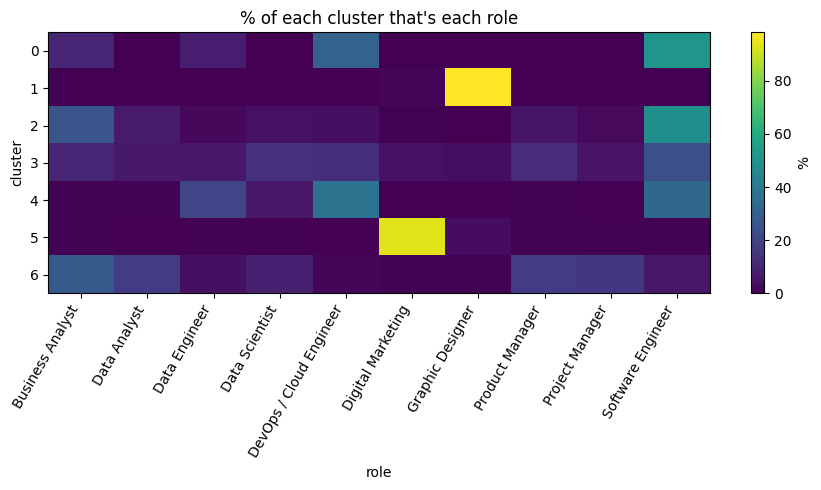

In [ ]:
heatmap_data = pd.crosstab(df['cluster'], df['role'], normalize='index') * 100
plt.figure(figsize=(9, 5))
plt.imshow(heatmap_data.values, aspect='auto', cmap='viridis')
plt.xticks(range(len(heatmap_data.columns)), heatmap_data.columns, rotation=60, ha='right')
plt.yticks(range(len(heatmap_data.index)), heatmap_data.index)
plt.xlabel("role"); plt.ylabel("cluster"); plt.title("% of each cluster that's each role")
plt.colorbar(label="%")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig6_cluster_role_heatmap.png", dpi=120)
plt.show()


Looking at the table and heatmap above: Graphic Designer, Digital Marketing, and DevOps/Cloud each land cleanly in their own cluster, dominated by one role. The clusters whose top words are generic corporate talk (not job-specific) are, unsurprisingly, mixed across many roles — exactly what you'd expect given the truncation problem from Section 4.


## 13. Business Takeaways

Only writing down what the actual numbers above support:

1. **Graphic Design, Digital Marketing, and DevOps/Cloud postings are genuinely identifiable from text alone** — their clusters are large and over 90% one role. A company could use just the description text (no title needed) to sort postings into these three buckets reliably.
2. **Analyst and manager-type roles blend together in writing** (Business Analyst, Data Analyst, Product Manager, Project Manager) — they share words like "requirements", "stakeholders", "delivery" more than they're distinct from each other. That's a real pattern in how these jobs are advertised, not a modelling mistake.
3. **A lot of postings just don't say enough in their first 500 characters to tell occupation apart** — this is a limitation of the data source, not something clustering can work around.
4. **The myGwork/LGBTQ-inclusive badge is a strong enough signal that it shows up as its own tiny cluster** — a minor but real finding about how some employers front-load that badge before any job content.


## 14. Limitations and Conclusion

**What actually limits this analysis:**
- **Truncation is the big one.** ~98.5% of postings are cut at 500 characters, and duplicate-text groups often span several different roles (Section 4) — meaning a chunk of this dataset simply doesn't have enough role-specific text to cluster correctly, no matter what I do to the model. This can't be fixed by better preprocessing.
- **The 10 roles here all skew tech/business/design** — this isn't a general finding about job postings everywhere, just about this specific India-focused, Adzuna-sourced slice.
- **Final silhouette is still low in absolute terms**, even after the SVD improvement. This is a real but modest result.
- **NMI/ARI against the roles are moderate.** They shouldn't be read as "the model found all 10 roles" — they're a rough agreement check, not the goal itself.
- **Boilerplate removal (Ablation A) genuinely didn't work** — I'm keeping that negative result in the notebook rather than hiding it.
- **I never compared my numbers to the paper's numbers**, on purpose (Section 2) — different data, so it wouldn't mean anything.

**Conclusion.** TF-IDF + SVD + K-Means finds real, useful clusters for occupations where the text survives truncation with actual job content intact (Graphic Design, Marketing, DevOps) — and generic, mixed clusters exactly where the EDA predicted truncation would erase that content. So the answer to the original question (Section 1) is: **yes, but unevenly** — and which occupations work or don't work is itself a useful, evidence-backed finding about this dataset, not just a limitation to apologize for.


In [ ]:
df[['job_id', 'role', 'cluster', 'description_length', 'description_is_truncated']].to_csv(
    f"{OUT_DIR}/final_cluster_assignments.csv", index=False
)

run_info = {
    "python_version": sys.version.split()[0],
    "pandas_version": pd.__version__,
    "sklearn_version": sklearn.__version__,
    "random_state": RNG,
    "dataset_rows": int(len(df)),
    "final_setup": "TF-IDF -> TruncatedSVD(50) -> K-Means",
    "final_k": FINAL_K,
    "final_silhouette": float(sil_final),
    "final_nmi_vs_role": float(nmi_final),
    "final_ari_vs_role": float(ari_final),
    "baseline_silhouette": float(sil_baseline),
    "baseline_nmi_vs_role": float(nmi_baseline),
    "ablations_kept": ["C: TruncatedSVD(50)"],
    "ablations_rejected": ["A: boilerplate removal", "B: bigrams"],
}
with open(f"{OUT_DIR}/run_metadata.json", "w") as f:
    json.dump(run_info, f, indent=2)

run_info


{'python_version': '3.10.13',
 'pandas_version': '2.3.3',
 'sklearn_version': '1.5.2',
 'random_state': 42,
 'dataset_rows': 7240,
 'final_setup': 'TF-IDF -> TruncatedSVD(50) -> K-Means',
 'final_k': 7,
 'final_silhouette': 0.08258695870904145,
 'final_nmi_vs_role': 0.29713839631676475,
 'final_ari_vs_role': 0.12227319499698143,
 'baseline_silhouette': 0.013448451948412621,
 'baseline_nmi_vs_role': 0.3424587888419571,
 'ablations_kept': ['C: TruncatedSVD(50)'],
 'ablations_rejected': ['A: boilerplate removal', 'B: bigrams']}

## 15. Saving the Final Model

Saving the fitted pieces (TF-IDF vectorizer, SVD, K-Means) to a `.pkl` file, so the same clustering can be re-applied to new postings later without re-fitting from scratch.


In [ ]:
import pickle

MODEL_PATH = "../models/text_mining_clusters.pkl"

model_bundle = {
    "vectorizer": vec_baseline,
    "svd": svd_final,
    "kmeans": km_final,
    "token_pattern": TOKEN_PATTERN,
    "stop_words": STOP_WORDS,
    "final_k": FINAL_K,
    "random_state": RNG,
}

with open(MODEL_PATH, "wb") as f:
    pickle.dump(model_bundle, f)

print("saved:", MODEL_PATH)


saved: ../models/text_mining_clusters.pkl
